# Titanic Survival Prediction: Classical ML Pipeline
## Week 1 Deliverable — Modular Architecture & Diagnostic Evaluation

This notebook demonstrates the end-to-end Machine Learning lifecycle adhering to **Clean Code** and **SOLID** principles:
- **Single Responsibility Principle (SRP)**: Distinct, decoupled modules for Ingestion, Imputation, Feature Engineering, Benchmarking, Tuning, Diagnostics, and Evaluation.
- **Open/Closed Principle (OCP)**: Candidate models and hyperparameter search grids are registered without modifying downstream execution pipelines.
- **Liskov Substitution Principle (LSP)**: All algorithms conform to scikit-learn's standard `BaseEstimator` interface.
- **Dependency Inversion Principle (DIP)**: Orchestration depends on abstract estimator interfaces and parameterized paths.


### Section 0: Environment Setup & Local Package Imports
> **SRP**: Configure plotting styling and import modular components from `src/`.

In [25]:
import os
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure local src/ package is discoverable
sys.path.append(os.path.abspath('.'))

# Preprocessing module (SRP: Data Cleaning, Imputation, Feature Engineering, Stratification)
from src.preprocessing import (
    load_raw_data,
    drop_uninformative_columns,
    impute_missing_values,
    engineer_domain_features,
    encode_categorical_features,
    perform_stratified_split,
    run_full_preprocessing_pipeline
)

# Training module (OCP/SRP: Model Registry, Stratified CV Arena, Hyperparameter Tuning)
from src.train import (
    get_model_registry,
    run_model_arena,
    get_hyperparameter_grids,
    tune_candidate_models,
    select_champion_model,
    tune_champion_model,
    save_model_artifact
)

# Evaluation module (SRP: Leaderboards, Diagnostics, Heatmaps, Feature Importance, ROC Curve)
from src.evaluate import (
    build_leaderboard,
    plot_model_arena,
    compare_tuned_models,
    evaluate_confusion_matrix,
    extract_feature_importances,
    evaluate_held_out_set
)

# Global configuration & paths
RANDOM_STATE = 42
TRAIN_PATH = 'data/train.csv' if os.path.exists('data/train.csv') else '../../data/train.csv'
TEST_PATH = 'data/test.csv' if os.path.exists('data/test.csv') else '../../data/test.csv'
print(f'[✓] Setup complete. Train CSV: {TRAIN_PATH} | Test CSV: {TEST_PATH}')


[✓] Setup complete. Train CSV: data/train.csv | Test CSV: data/test.csv


### Section 1: Data Ingestion & Hygiene Audit
> **SRP**: Ingest raw datasets, verify shapes, and drop uninformative passenger identifiers (`PassengerId`, `Ticket`, `Cabin`).

In [26]:
# Ingest raw datasets
raw_train, raw_test, test_ids = load_raw_data(TRAIN_PATH, TEST_PATH)
print(f'Raw Train shape: {raw_train.shape} | Raw Test shape: {raw_test.shape}')

# Drop uninformative identifiers
cleaned_train = drop_uninformative_columns(raw_train)
cleaned_test = drop_uninformative_columns(raw_test)

# Inspect missing value audit
missing_summary = pd.DataFrame({
    'Train Missing': cleaned_train.isnull().sum(),
    'Train Missing %': (cleaned_train.isnull().mean() * 100).round(1),
    'Test Missing': cleaned_test.isnull().sum(),
    'Test Missing %': (cleaned_test.isnull().mean() * 100).round(1)
}).loc[lambda df: (df['Train Missing'] > 0) | (df['Test Missing'] > 0)]

print('[*] Missing Values Audit:')
missing_summary


Raw Train shape: (891, 12) | Raw Test shape: (418, 11)
[*] Missing Values Audit:


,Train Missing,Train Missing %,Test Missing,Test Missing %
Age,177,19.9,86.0,20.6
Embarked,2,0.2,0.0,0.0
Fare,0,0.0,1.0,0.2


### Section 2: Statistical Imputation (Zero Data Leakage)
> **Data Leakage Rule**: Medians (`Age`, `Fare`) and mode (`Embarked`) are learned strictly on the training set and applied to both train and test.

In [27]:
imputed_train, imputed_test = impute_missing_values(cleaned_train, cleaned_test)

print('[✓] Null counts after statistical imputation:')
print(f'    Train nulls: {imputed_train.isnull().sum().sum()}')
print(f'    Test nulls:  {imputed_test.isnull().sum().sum()}')


[✓] Null counts after statistical imputation:
    Train nulls: 0
    Test nulls:  0


### Section 3: Domain Feature Engineering & Categorical Encoding
> **SRP**: Extract social titles (`Title`), family dynamics (`FamilySize`, `IsAlone`), and apply one-hot encoding (`Embarked`, `Title`).

In [28]:
# Feature Engineering
fe_train = engineer_domain_features(imputed_train)
fe_test = engineer_domain_features(imputed_test)

# One-Hot Encoding
enc_train = encode_categorical_features(fe_train)
enc_test = encode_categorical_features(fe_test)

print(f'[✓] Transformed training shape: {enc_train.shape}')
print(f'    Feature list ({len(enc_train.columns) - 1}): {[c for c in enc_train.columns if c != "Survived"]}')
enc_train.head()


[✓] Transformed training shape: (891, 15)
    Feature list (14): ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,2,0,0,1,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,2,0,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,1,1,0,1,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,2,0,0,1,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,1,1,0,1,0,1,0,0


### Section 4: Stratified Splitting Verification
> **Stratification Rule**: Preserve the ~61.6% (Perished) : 38.4% (Survived) class ratio across train (80% / 712 rows) and validation (20% / 179 rows).

In [29]:
X = enc_train.drop(columns=['Survived'])
y = enc_train['Survived']
X_train, X_val, y_train, y_val = perform_stratified_split(X, y, random_state=RANDOM_STATE)

split_df = pd.DataFrame({
    'Split': ['Full Dataset', 'X_train (80%)', 'X_val (20%)'],
    'Samples': [len(enc_train), len(X_train), len(X_val)],
    'Perished (0)': [int((enc_train['Survived'] == 0).sum()), int((y_train == 0).sum()), int((y_val == 0).sum())],
    'Survived (1)': [int((enc_train['Survived'] == 1).sum()), int((y_train == 1).sum()), int((y_val == 1).sum())],
    'Survival Rate %': [
        round(enc_train['Survived'].mean() * 100, 2),
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2)
    ]
})
split_df


[*] Split complete: X_train (712, 14) | X_val (179, 14)
    Train survival rate: 0.383 | Val survival rate: 0.385


,Split,Samples,Perished (0),Survived (1),Survival Rate %
0,Full Dataset,891,549,342,38.38
1,X_train (80%),712,439,273,38.34
2,X_val (20%),179,110,69,38.55


### Section 5: Model Registry & 5-Fold Stratified Cross-Validation Arena
> **OCP & LSP**: Instantiate candidate models conforming to `BaseEstimator`. Benchmark using 5-Fold Stratified CV, evaluate the Overfit Gap $\Delta = \text{Train F1} - \text{Val F1}$, and flag models with $\Delta > 0.08$.

In [30]:
# Instantiate Model Registry
models = get_model_registry(random_state=RANDOM_STATE)

# Run 5-Fold Stratified CV Arena
arena_results = run_model_arena(models, X_train, y_train, cv_splits=5)

# Build Leaderboard with Overfit Gap analysis
leaderboard = build_leaderboard(arena_results, sort_by='Test F1')
leaderboard


[*] Benchmarking Dummy...
[*] Benchmarking Logistic Regression...
[*] Benchmarking Decision Tree...
[*] Benchmarking Random Forest...
[*] Benchmarking XGBoost...


,Model,Test F1,Train F1,F1 Gap (Delta),Test Accuracy,Train Accuracy,Test ROC-AUC,Status
0,Logistic Regression,0.7625,0.7708,0.0083,0.8231,0.8290,0.8657,HEALTHY
1,XGBoost,0.7461,0.9713,0.2252,0.8104,0.9782,0.8816,OVERFITTING
2,Random Forest,0.7442,0.9802,0.2360,0.8062,0.9849,0.8698,OVERFITTING
3,Decision Tree,0.7115,0.9801,0.2686,0.7781,0.9849,0.7642,OVERFITTING
4,Dummy,0.0000,0.0000,0.0000,0.6166,0.6166,0.5000,HEALTHY


#### Visual Leaderboard: Validation Performance & Overfit Gap Analysis
> Plots the side-by-side comparison of Validation F1 vs. Training F1 for each candidate model, visually highlighting overfit margins.

[*] Saved arena benchmark plot to: reports/arena_benchmark.png


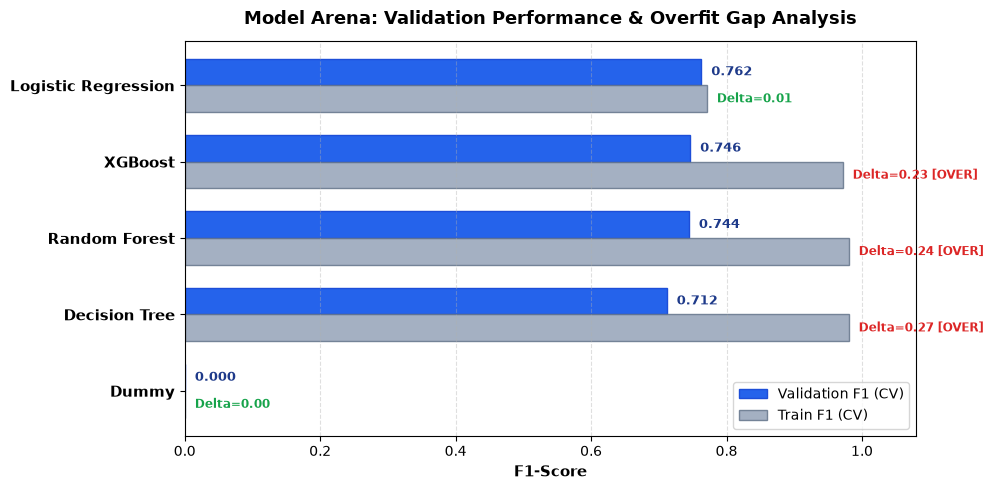

In [31]:
# Render Visual Arena Benchmark inline
plot_model_arena(leaderboard, save_fig_path='reports/arena_benchmark.png', show_plot=True);


### Section 6: Out-of-Fold Error Analysis & Confusion Matrix Heatmap
> **SRP**: Analyze error distributions (Type I False Positives vs. Type II False Negatives) via out-of-fold `cross_val_predict` on Random Forest.

[*] Saved confusion matrix plot to: reports/confusion_matrix.png


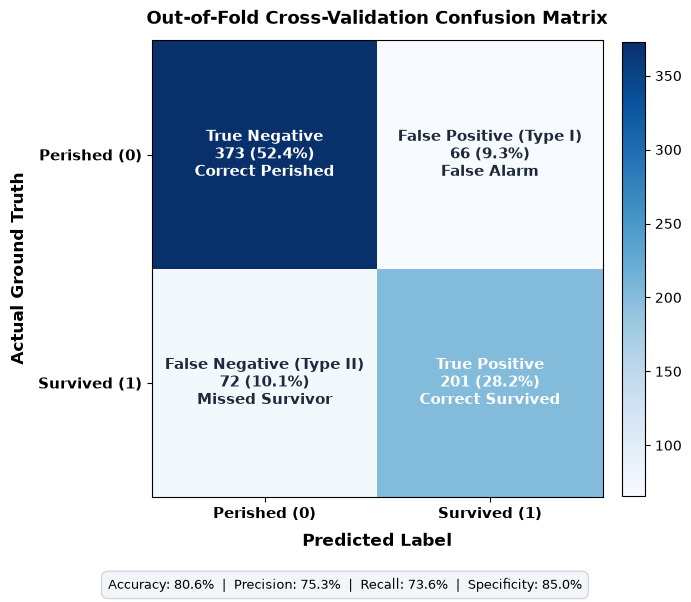

,Error Classification,Count
0,True Negatives (Correct Perished),373
1,False Positives (Type I Error),66
2,False Negatives (Type II Error),72
3,True Positives (Correct Survived),201


In [32]:
cm, breakdown = evaluate_confusion_matrix(
    models['Random Forest'],
    X_train,
    y_train,
    cv_splits=5,
    random_state=RANDOM_STATE,
    save_fig_path='reports/confusion_matrix.png',
    show_plot=True
)

pd.DataFrame(list(breakdown.items()), columns=['Error Classification', 'Count'])


### Section 7: Hyperparameter Tuning & Tournament Champion Selection
> **OCP**: Systematically optimize hyperparameters with `GridSearchCV` and declare the official Champion model.

In [33]:
param_grids = get_hyperparameter_grids()
tuning_results = tune_candidate_models(
    models=models,
    param_grids=param_grids,
    X_train=X_train,
    y_train=y_train,
    cv_splits=5,
    scoring='f1',
    random_state=RANDOM_STATE
)

# Select Champion Model and print tournament banner
champion_name, champion_estimator, best_params, best_score = select_champion_model(tuning_results)
comparison_df = compare_tuned_models(tuning_results, baseline_results=arena_results)
comparison_df


[*] Tuning Logistic Regression with GridSearchCV...
    - Logistic Regression Best F1: 0.7625 | Params: {'logisticregression__C': 1.0}
[*] Tuning Decision Tree with GridSearchCV...
    - Decision Tree Best F1: 0.7602 | Params: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
[*] Tuning Random Forest with GridSearchCV...
    - Random Forest Best F1: 0.7679 | Params: {'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
[*] Tuning XGBoost with GridSearchCV...
    - XGBoost Best F1: 0.7666 | Params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100, 'subsample': 1.0}
[*] Overall Champion Selected: Random Forest (F1: 0.7679)


,Rank,Model,Tuned CV F1,Baseline F1,Delta Gain,Best Parameters
0,1,Random Forest,0.7679,0.7442,0.0237,"max_depth=4, min_samples_leaf=2, min_samples_s..."
1,2,XGBoost,0.7666,0.7461,0.0205,"learning_rate=0.1, max_depth=4, n_estimators=1..."
2,3,Logistic Regression,0.7625,0.7625,0.0000,C=1.0
3,4,Decision Tree,0.7602,0.7115,0.0487,"max_depth=3, min_samples_leaf=1, min_samples_s..."


### Section 8: Predictive Feature Importances & Pristine Held-Out Evaluation
> **Final Verification**: Extract Gini feature importances for the champion model, then evaluate strictly on the untouched validation set (179 rows) with the ROC Curve.

[*] Saved feature importance plot to: reports/feature_importance.png


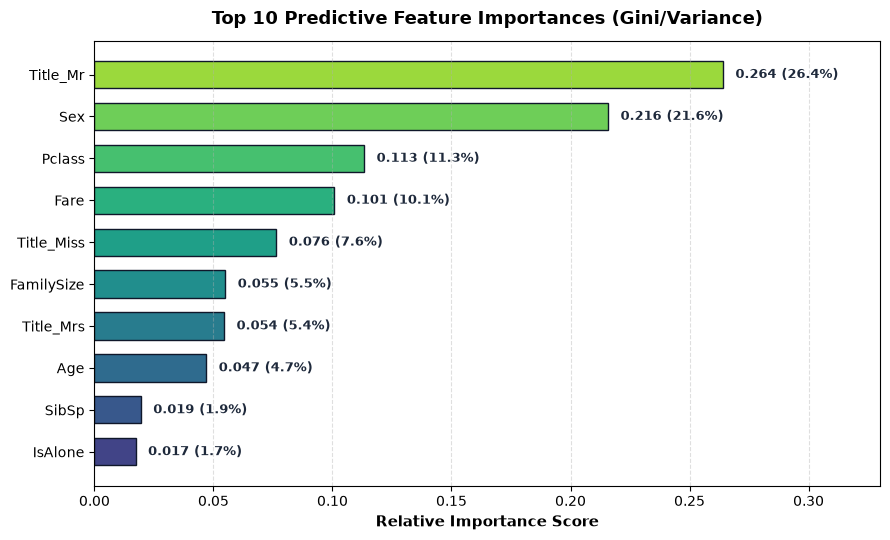

In [34]:
# Fit champion on full training set
champion_estimator.fit(X_train, y_train)

# Top Feature Importances Horizontal Bar Chart
importances = extract_feature_importances(
    champion_estimator,
    feature_names=list(X_train.columns),
    top_n=10,
    save_fig_path='reports/feature_importance.png',
    show_plot=True
);


### [GUIDE] Deep Dive: Demystifying the ROC-AUC Curve (Mental Model & Interpretation Guide)

#### 1. Why Accuracy Alone Is Misleading on Titanic
On the Titanic dataset, ~61.6% of passengers perished and ~38.4% survived.
If a naive baseline simply predicts **"Everyone Perished"**, it achieves **61.6% Accuracy** while having **zero predictive value**!
Furthermore, accuracy assumes an arbitrary fixed decision threshold of `0.50` (50% probability).

---

#### 2. What the Two Axes Actually Mean
- **Y-Axis: True Positive Rate (TPR / Recall)**:
  $$\text{TPR} = \frac{\text{True Positives}}{\text{Actual Survivors}} = \frac{\text{Survivors Correctly Caught}}{\text{Total Real Survivors}}$$
  *Goal: We want this as close to 1.0 (100%) as possible!*

- **X-Axis: False Positive Rate (FPR / 1 - Specificity)**:
  $$\text{FPR} = \frac{\text{False Positives}}{\text{Actual Perished}} = \frac{\text{Perished Passengers Falsely Called Survivors}}{\text{Total Real Perished}}$$
  *Goal: We want this as close to 0.0 (0% false alarms) as possible!*

---

#### 3. How the Curve Is Built (The Sliding Cutoff Concept)
Instead of outputting a hard `0` or `1`, our Random Forest outputs a **probability of survival** (e.g. 72% chance of surviving).
The ROC curve sweeps every possible decision cutoff from **1.0 down to 0.0**:

| Cutoff Setting | Model Strategy | TPR (Y-Axis) | FPR (X-Axis) |
| :--- | :--- | :--- | :--- |
| **Strict (0.90)** | Only predicts 'Survived' when 100% positive | Low (misses many real survivors) | 0% (zero false alarms) |
| **Optimal (0.46)** | **Balanced Sweet Spot (Youden's J Index)** | **High (84.1% caught)** | **Low (15.5% false alarms)** |
| **Lenient (0.10)** | Predicts 'Survived' at any hint of life | 100% (catches all survivors) | High (many dead passengers falsely marked alive) |

---

#### 4. What Does the Shaded Area (AUC = 0.855) Mean?
- **AUC = 0.50 (Dashed Diagonal Line)**: Represents **pure random guessing** (like flipping a coin). Zero ranking ability.
- **AUC = 1.00 (Top-Left Corner)**: Represents **perfection** (100% survivors caught, 0% false alarms).
- **AUC = 0.855 (Our Champion Model)**:
  > **Plain English**: If you randomly pick **one passenger who survived** and **one who perished**, there is an **85.5% probability** that our Random Forest assigns a higher survival probability to the person who actually survived!

---

#### 5. What Does the Red Dot Show? (`Optimal Cutoff = 0.46`)
Standard libraries default to `0.50`. However, using **Youden's J Statistic** ($J = \text{TPR} - \text{FPR}$), the optimal operating point on our held-out test data is **`0.46`**.
At this cutoff, the champion model successfully captures **84.1% of survivors** while maintaining a false alarm rate of only **15.5%**.


         HELD-OUT VALIDATION SET EVALUATION
Accuracy:  0.8101
F1-Score:  0.7385
ROC-AUC:   0.8546

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179

[*] Saved ROC curve plot to: reports/roc_curve.png


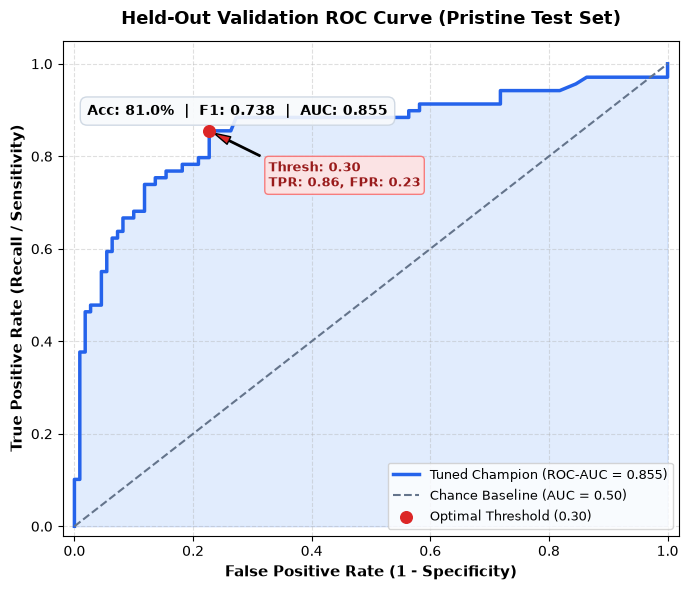

In [37]:
# Strict Held-Out Evaluation & ROC-AUC Curve with Youden's J optimal cutoff
held_out_metrics = evaluate_held_out_set(
    champion_estimator,
    X_val,
    y_val,
    save_fig_path='reports/roc_curve.png',
    show_plot=True
);


In [36]:
# Persist Champion Model Artifact
save_model_artifact(champion_estimator, 'models/champion_model.joblib')
print(f'[✓] Tournament complete! Model artifact saved for Champion: {champion_name}')


[*] Successfully saved model artifact to: models/champion_model.joblib
[✓] Tournament complete! Model artifact saved for Champion: Random Forest
